In [1]:
import importlib
import carsharing_data as csd
importlib.reload(csd)

<module 'carsharing_data' from '/home/students/s366283/Smart mobility/ICT4SM/TP1/carsharing_data.py'>

In [8]:
import numpy as np
import matplotlib.pyplot as plt
bookings_f2, parkings_f2 = csd.get_filtered_data(refresh=True)
# dicts {"Torino": df, "Columbus": df, "Frankfurt": df}

bookings  Torino     zone = [    0.8,     38.0] min -> 238053/264503 gardés (90.0%)
bookings  Columbus   zone = [    0.8,     44.0] min -> 47679/52976 gardés (90.0%)
bookings  Frankfurt  zone = [    0.8,     60.1] min -> 131902/146557 gardés (90.0%)
parkings  Torino     zone = [    0.8,    410.4] min -> 238088/264542 gardés (90.0%)
parkings  Columbus   zone = [    1.5,   1719.7] min -> 47631/52923 gardés (90.0%)
parkings  Frankfurt  zone = [    0.8,    432.1] min -> 132169/146854 gardés (90.0%)


In [9]:
bookings_f2, parkings_f2, extra2 = csd.get_filtered_data(return_extra=True)
extra2["raw"]["bookings"]["Torino"]       # non filtré
extra2["zones"][("bookings", "Torino")]   # (a, b) en minutes

bookings  Torino     zone = [    0.8,     38.0] min -> 238053/264503 gardés (90.0%)
bookings  Columbus   zone = [    0.8,     44.0] min -> 47679/52976 gardés (90.0%)
bookings  Frankfurt  zone = [    0.8,     60.1] min -> 131902/146557 gardés (90.0%)
parkings  Torino     zone = [    0.8,    410.4] min -> 238088/264542 gardés (90.0%)
parkings  Columbus   zone = [    1.5,   1719.7] min -> 47631/52923 gardés (90.0%)
parkings  Frankfurt  zone = [    0.8,    432.1] min -> 132169/146854 gardés (90.0%)


(np.float64(0.7666666666666667), np.float64(38.0))

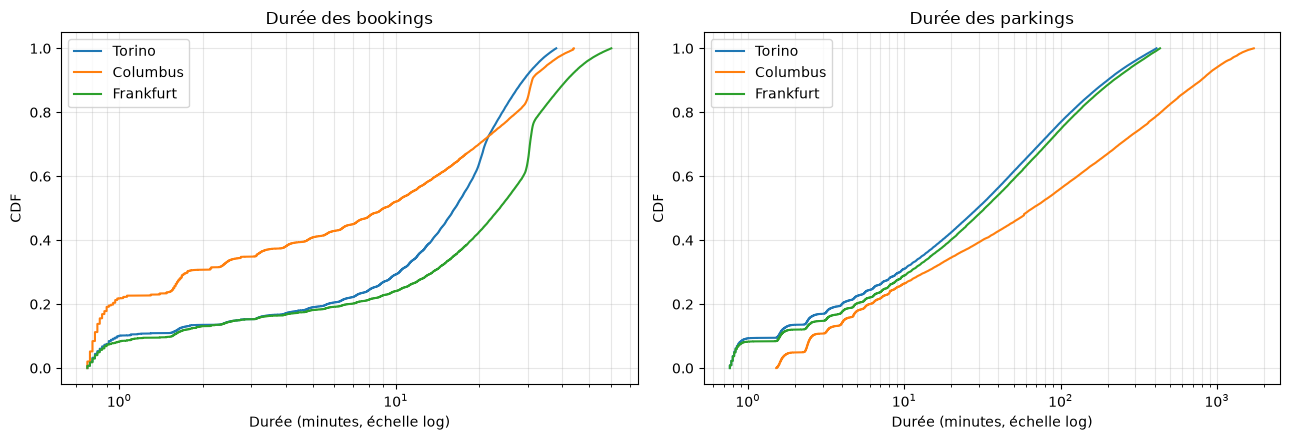

In [10]:
def plot_cdf(data_dict, title, ax):
    for city, df in data_dict.items():
        x = np.sort(df["duration_min"].values)
        x = x[x > 0]                                  # nécessaire pour l'axe log
        y = np.arange(1, len(x)+1) / len(x)
        ax.plot(x, y, label=city)
    ax.set_xscale("log")
    ax.set_xlabel("Durée (minutes, échelle log)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings_f2, "Durée des bookings", axes[0])
plot_cdf(parkings_f2, "Durée des parkings", axes[1])
plt.tight_layout(); plt.show()

In [11]:
csd.check_data(extra2["raw"])                 # données brutes (bookings + parkings)
csd.check_data(bookings_f2)                   # ou un seul dict {ville: df}, filtré par exempl

[bookings/Torino] jours SANS données : ['2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-11-09', '2017-11-10', '2017-11-11', '2017-11-12', '2017-12-10']
[bookings/Columbus] jours SANS données : ['2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-11-09', '2017-11-10', '2017-11-11', '2017-11-12', '2017-12-10']
[bookings/Frankfurt] jours SANS données : ['2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-11-09', '2017-11-10', '2017-11-11', '2017-11-12', '2017-12-10']
[parkings/Torino] jours SANS données : ['2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-11-09', '2017-11-10', '2017-11-11', '2017-11-12', '2017-12-10']
[parkings/Torino] jours à activité très faible (< 30% de la médiane) : ['2017-11-02']
[parkings/Columbus] jours SANS données : ['2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-1

,lignes,première date,dernière date,jours couverts,jours manquants,jours faibles,hors période,nulls,durée <= 0,doublons,ok
jeu,,,,,,,,,,,
Torino,238053,2017-11-01 00:00,2018-01-31 13:09,81/92,11,0,0,0,0,30523,False
Columbus,47679,2017-11-01 00:00,2018-01-31 13:10,81/92,11,0,0,0,0,5050,False
Frankfurt,131902,2017-11-01 00:01,2018-01-31 13:04,81/92,11,0,0,0,0,12260,False


In [12]:
collection = bookings_f2
collection["Torino"]



,init_address,vendor,final_time,final_address,init_time,origin_destination,duration,day,week,iso_year,dow,hour,duration_min
0,"Corso Monte Lungo, 2-16, 10134 Torino TO",car2go,1517404245,"Corso Monte Lungo, 2-16, 10134 Torino TO",1517404195,"{'type': 'LineString', 'coordinates': [[7.6553...",50,2018-01-31,5,2018,3,14,0.833333
1,"Via Umberto Biancamano, 1, 10121 Torino TO",car2go,1517404148,"Via Umberto Biancamano, 1, 10121 Torino TO",1517404092,"{'type': 'LineString', 'coordinates': [[7.6759...",56,2018-01-31,5,2018,3,14,0.933333
2,"Via Luigi Leonardo Colli, 2, 10128 Torino TO",car2go,1517404245,"Corso Duca degli Abruzzi, 75, 10129 Torino TO",1517404092,"{'type': 'LineString', 'coordinates': [[7.6649...",153,2018-01-31,5,2018,3,14,2.550000
3,"Via Achille Loria, 6, 10128 Torino TO",car2go,1517404092,"Via Achille Loria, 6, 10128 Torino TO",1517404040,"{'type': 'LineString', 'coordinates': [[7.6683...",52,2018-01-31,5,2018,3,14,0.866667
4,"Via Rodolfo Montevecchio, 30, 10128 Torino TO",car2go,1517404092,"Via Rodolfo Montevecchio, 30, 10128 Torino TO",1517404040,"{'type': 'LineString', 'coordinates': [[7.6693...",52,2018-01-31,5,2018,3,14,0.866667
...,...,...,...,...,...,...,...,...,...,...,...,...,...
264498,"Corso Duca degli Abruzzi, 72, 10129 Torino TO",car2go,1509496369,"Via Villarbasse, 18, 10141 Torino TO",1509494455,"{'type': 'LineString', 'coordinates': [[7.6581...",1914,2017-11-01,44,2017,3,1,31.900000
264499,"Via Luigi Capriolo, 5, 10139 Torino TO",car2go,1509496028,"Corso Palermo, 124, 10154 Torino TO",1509494455,"{'type': 'LineString', 'coordinates': [[7.6423...",1573,2017-11-01,44,2017,3,1,26.216667
264500,"Via Sagra S. Michele, 14-32, 10139 Torino TO",car2go,1509495244,"Corso XI Febbraio, 24-30, 10152 Torino TO",1509494455,"{'type': 'LineString', 'coordinates': [[7.6311...",789,2017-11-01,44,2017,3,1,13.150000
264501,"Via Antonio Bertola, 15/B, 10121 Torino TO",car2go,1509494455,"Via Antonio Bertola, 15/B, 10121 Torino TO",1509494400,"{'type': 'LineString', 'coordinates': [[7.6809...",55,2017-11-01,44,2017,3,1,0.916667
